# Week 3 · Class 1 — Data Cleaning & Exploratory Data Analysis 🔍📊

**2 × 60 min** · tools: `pandas`, `matplotlib`, `seaborn`, `scipy`

| Part | Time | Content |
|---|---|---|
| **Part 1** | 60 min | What is EDA · variable types · **data cleaning** · **univariate analysis** |
| **Part 2** | 60 min | **Bivariate analysis**: categorical × categorical · categorical × numerical · numerical × numerical · Pearson vs Spearman vs Kendall · normality (QQ plot) |

**Datasets**
- 🧑‍💼 **IBM HR Attrition** — 1,470 employees: age, income, job role, satisfaction… and whether they **quit** (`Attrition`).
- 🌍 **Significant Earthquakes 1965–2016** — 23,409 events: date, location, depth, magnitude, type.

> 🧪 **Saturday labs:** you will apply *every* technique of this notebook to the **Amazon UK products** dataset. Each part ends with a table *lab task → section of this notebook*.

## 0. What is EDA? 🤔

**Exploratory Data Analysis** = getting to know your data *before* modelling or reporting:
1. **Check quality** — can we trust the data? → *cleaning*
2. **Describe** each variable alone → *univariate analysis*
3. **Relate** variables to each other → *bivariate analysis*
4. Write down **insights** in business language.

Every study has a **purpose**. Ours: *why do employees leave IBM?* — so `Attrition` is our most important variable.

### Variable types decide everything

| Type | Sub-type | IBM / Earthquakes | Amazon lab |
|---|---|---|---|
| **Categorical** | nominal (no order) | `JobRole`, `Department`, `Attrition`, `Type` | `category`, `isBestSeller` |
| | ordinal (ordered) | `Education` 1–5, `JobSatisfaction` 1–4 | `stars` |
| **Numerical** | discrete (counts) | `NumCompaniesWorked`, `YearsAtCompany` | `reviews`, `boughtInLastMonth` |
| | continuous | `MonthlyIncome`, `Depth`, `Magnitude` | `price` |

> 💡 Always ask first: *what type is this column?* The type tells you which statistics and plots make sense.
> ⚠️ A number is not always numerical: `Education = 3` is a **code** for "Bachelor", not a quantity.

## ⚙️ Setup

📁 Put `IBM_HR_ATTRITION.csv` and `earthquakes.csv` next to this notebook.
In **Colab**: click the folder icon on the left and drag the two files in (or change the paths below).

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", None)       # IBM has 35 columns: show them all

In [6]:
ibm_raw = pd.read_csv("../data/IBM_HR_ATTRITION.csv")
eq_raw = pd.read_csv("../data/earthquakes.csv")
print("IBM:", ibm_raw.shape, "| Earthquakes:", eq_raw.shape)

IBM: (1470, 35) | Earthquakes: (23409, 21)


---
# PART 1 · Data cleaning & univariate analysis (60 min)
---
## 1. First look: never touch before you look 👀

| Command | Question it answers |
|---|---|
| `df.shape` | how big? |
| `df.head()` / `df.sample()` | what does a row look like? |
| `df.info()` | which types? how many non-null? |
| `df.describe(include="all")` | ranges, counts, most frequent values |
| `df[col].value_counts()` | which categories? typos? |
| `df.isna().sum()` | where are the holes? |
| `df.nunique()` | how many different values per column? |

In [7]:
# ✍️ live coding
eq = eq_raw.copy()
eq.head()

,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,Magnitude Error,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,NaN,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,NaN,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,NaN,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,NaN,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,NaN,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


In [8]:
# ✍️ live coding
eq.info()

<class 'pandas.DataFrame'>
RangeIndex: 23409 entries, 0 to 23408
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        23409 non-null  str    
 1   Time                        23409 non-null  str    
 2   Latitude                    23409 non-null  float64
 3   Longitude                   23409 non-null  float64
 4   Type                        23409 non-null  str    
 5   Depth                       23409 non-null  float64
 6   Depth Error                 4460 non-null   float64
 7   Depth Seismic Stations      7096 non-null   float64
 8   Magnitude                   23409 non-null  float64
 9   Magnitude Type              23406 non-null  str    
 10  Magnitude Error             327 non-null    float64
 11  Magnitude Seismic Stations  2564 non-null   float64
 12  Azimuthal Gap               7298 non-null   float64
 13  Horizontal Distance         1604 non-null 

In [9]:
# ✍️ live coding
eq.isna().mean().mul(100).round(1).sort_values(ascending=False)

Magnitude Error               98.6
Horizontal Error              95.1
Horizontal Distance           93.1
Magnitude Seismic Stations    89.0
Depth Error                   80.9
Depth Seismic Stations        69.7
Azimuthal Gap                 68.8
Root Mean Square              25.9
Magnitude Source               0.0
Location Source                0.0
Source                         0.0
ID                             0.0
Date                           0.0
Time                           0.0
Magnitude Type                 0.0
Magnitude                      0.0
Depth                          0.0
Type                           0.0
Longitude                      0.0
Latitude                       0.0
Status                         0.0
dtype: float64

🚨 **Surprises** (write them down — it's your cleaning to-do list):
- `Date` and `Time` are text (`object`), not dates.
- Column names contain spaces (`"Depth Error"`) → annoying to type.
- Many technical columns are **70–99% empty**.
- `Type` is not only earthquakes!

In [11]:
# ✍️ live coding
eq["Type"].value_counts()


Type
Earthquake           23229
Nuclear Explosion      175
Explosion                4
Rock Burst               1
Name: count, dtype: int64

In [13]:
# ✍️ live coding
eq.describe(include="all")

,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,Magnitude Error,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
count,23409,23409,23409.000000,23409.000000,23409,23409.000000,4460.000000,7096.000000,23409.000000,23406,327.000000,2564.000000,7298.000000,1604.000000,1156.000000,17350.000000,23409,23409,23409,23409,23409
unique,12398,20469,NaN,NaN,4,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,NaN,NaN,23409,13,48,24,2
top,03/11/2011,02:56:58,NaN,NaN,Earthquake,NaN,NaN,NaN,NaN,MW,NaN,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,US,US,US,Reviewed
freq,128,5,NaN,NaN,23229,NaN,NaN,NaN,NaN,7721,NaN,NaN,NaN,NaN,NaN,NaN,1,20627,20347,10457,20770
mean,NaN,NaN,1.678763,39.636726,NaN,70.748526,4.991118,275.362176,5.882558,NaN,0.071820,48.944618,44.165158,3.992660,7.662759,1.022766,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,30.113379,125.514881,NaN,122.605748,4.873905,162.152976,0.423084,NaN,0.051466,62.943106,32.143388,5.377262,10.430396,0.188544,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,-77.080000,-179.997000,NaN,-1.100000,0.000000,0.000000,5.500000,NaN,0.000000,0.000000,0.000000,0.004505,0.085000,0.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,-18.652000,-76.352000,NaN,14.530000,1.800000,146.000000,5.600000,NaN,0.046000,10.000000,24.100000,0.968750,5.300000,0.900000,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,-3.569000,103.981000,NaN,33.000000,3.500000,255.000000,5.700000,NaN,0.059000,28.000000,36.000000,2.319500,6.700000,1.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,26.188000,145.027000,NaN,54.000000,6.300000,384.000000,6.000000,NaN,0.075500,66.000000,54.000000,4.724500,8.100000,1.130000,NaN,NaN,NaN,NaN,NaN


In [15]:
eq.columns = eq.columns.str.strip().str.lower().str.replace(" ", "_")
eq.columns.tolist()

['date',
 'time',
 'latitude',
 'longitude',
 'type',
 'depth',
 'depth_error',
 'depth_seismic_stations',
 'magnitude',
 'magnitude_type',
 'magnitude_error',
 'magnitude_seismic_stations',
 'azimuthal_gap',
 'horizontal_distance',
 'horizontal_error',
 'root_mean_square',
 'id',
 'source',
 'location_source',
 'magnitude_source',
 'status']

In [20]:
eq
eq["year_tmp"] = eq["date"].str[-4:].astype(int)
eq.depth_error.isna().sum()
eq.groupby(eq["year_tmp"] //10 *10 )["depth_error"].apply(lambda s: s.isna().mean() * 100).round(0) # 1965 //10 = 196 ## * 10 --> 1960


year_tmp
1960    100.0
1970    100.0
1980     73.0
1990     91.0
2000     87.0
2010     40.0
Name: depth_error, dtype: float64

👀 `Depth` has a **negative** minimum. Is that possible? (Answer: a few hundred metres above sea level — mountains! Small negatives are plausible. Domain knowledge decides, not pandas.)

In [21]:
too_empty = eq.columns[eq.isna().mean() > 0.5]
print("Dropping:", too_empty.tolist())
eq = eq.drop(columns=too_empty.tolist() + ["year_tmp"])
eq.shape

Dropping: ['depth_error', 'depth_seismic_stations', 'magnitude_error', 'magnitude_seismic_stations', 'azimuthal_gap', 'horizontal_distance', 'horizontal_error']


(23409, 14)

In [23]:
eq
eq["date"] = pd.to_datetime(eq["date"] + " " + eq["time"], format="%m/%d/%Y %H:%M:%S")
eq = eq.drop(columns="time")
eq["year"] = eq["date"].dt.year
eq[["date", "year"]].dtypes

date    datetime64[us]
year             int32
dtype: object

In [24]:
eq

,date,latitude,longitude,type,depth,magnitude,magnitude_type,root_mean_square,id,source,location_source,magnitude_source,status,year
0,1965-01-02 13:44:18,19.2460,145.6160,Earthquake,131.60,6.0,MW,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
1,1965-01-04 11:29:49,1.8630,127.3520,Earthquake,80.00,5.8,MW,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
2,1965-01-05 18:05:58,-20.5790,-173.9720,Earthquake,20.00,6.2,MW,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
3,1965-01-08 18:49:43,-59.0760,-23.5570,Earthquake,15.00,5.8,MW,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
4,1965-01-09 13:32:50,11.9380,126.4270,Earthquake,15.00,5.8,MW,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23404,2016-12-28 08:22:12,38.3917,-118.8941,Earthquake,12.30,5.6,ML,0.1898,NN00570710,NN,NN,NN,Reviewed,2016
23405,2016-12-28 09:13:47,38.3777,-118.8957,Earthquake,8.80,5.5,ML,0.2187,NN00570744,NN,NN,NN,Reviewed,2016
23406,2016-12-28 12:38:51,36.9179,140.4262,Earthquake,10.00,5.9,MWW,1.5200,US10007NAF,US,US,US,Reviewed,2016
23407,2016-12-29 22:30:19,-9.0283,118.6639,Earthquake,79.00,6.3,MWW,1.4300,US10007NL0,US,US,US,Reviewed,2016


## 2. Cleaning the earthquakes data 🧹

### 2.1 Column names
`snake_case` names are easier to type and work with `df.column_name`.

In [25]:
# ✍️ live coding
print("Exact duplicate rows:", eq.duplicated().sum())
print("Duplicated ids:", eq["id"].duplicated().sum())

Exact duplicate rows: 0
Duplicated ids: 0


### 2.2 Missing values — *why* are they missing?

| Mechanism | Meaning | Example | What to do |
|---|---|---|---|
| **MCAR** — completely at random | missingness unrelated to anything | a form lost by accident | dropping is safe |
| **MAR** — explained by *other* columns | depends on an observed column | old (1960s) events have no error estimates | analyse per group / be careful with trends |
| **MNAR** — explained by the *missing value itself* | depends on the value we don't see | high earners refuse to report income | flag it, be careful with conclusions |

Options: **drop rows** (`dropna`), **drop columns** (mostly empty), **fill** (`fillna`: median for skewed numbers, mode for categories), or **flag** (new column `x_missing`).

In [29]:
# ✍️ live coding
eq.type.value_counts()
earthquakes = eq[eq.type == "Earthquake"].copy()
earthquakes.shape

(23229, 14)

💡 Missing error measurements depend on the **decade** (old instruments didn't report them) → MAR. For our analysis we only need date, location, type, depth and magnitude, so we **drop columns** that are more than 50% empty.

In [30]:
# ✍️ live coding
earthquakes

,date,latitude,longitude,type,depth,magnitude,magnitude_type,root_mean_square,id,source,location_source,magnitude_source,status,year
0,1965-01-02 13:44:18,19.2460,145.6160,Earthquake,131.60,6.0,MW,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
1,1965-01-04 11:29:49,1.8630,127.3520,Earthquake,80.00,5.8,MW,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
2,1965-01-05 18:05:58,-20.5790,-173.9720,Earthquake,20.00,6.2,MW,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
3,1965-01-08 18:49:43,-59.0760,-23.5570,Earthquake,15.00,5.8,MW,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
4,1965-01-09 13:32:50,11.9380,126.4270,Earthquake,15.00,5.8,MW,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23404,2016-12-28 08:22:12,38.3917,-118.8941,Earthquake,12.30,5.6,ML,0.1898,NN00570710,NN,NN,NN,Reviewed,2016
23405,2016-12-28 09:13:47,38.3777,-118.8957,Earthquake,8.80,5.5,ML,0.2187,NN00570744,NN,NN,NN,Reviewed,2016
23406,2016-12-28 12:38:51,36.9179,140.4262,Earthquake,10.00,5.9,MWW,1.5200,US10007NAF,US,US,US,Reviewed,2016
23407,2016-12-29 22:30:19,-9.0283,118.6639,Earthquake,79.00,6.3,MWW,1.4300,US10007NL0,US,US,US,Reviewed,2016


In [31]:
## IBM data
ibm = ibm_raw.copy()

In [33]:
print("missing values", ibm.isna().sum())
print("duplicated values", ibm.duplicated().sum())

missing values Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole       

In [35]:
ibm.Education.value_counts()

Education
3    572
4    398
2    282
1    170
5     48
Name: count, dtype: int64

### 2.3 Data types: text → datetime
`"01/02/1965"` — is it 1 February or 2 January? Check the values: the first number goes up to 12 and the second up to 31 → **month/day/year** (US format). Always pass the `format`!

In [36]:
# ✍️ live coding
ibm["EducationLevel"] = ibm["Education"].map(
    {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"})
ibm["EducationLevel"] = pd.Categorical(
    ibm["EducationLevel"], categories=["Below College", "College", "Bachelor", "Master", "Doctor"], ordered=True)
ibm 



,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,EducationLevel
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5,College
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7,Below College
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0,College
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0,Master
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2,Below College
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,3,Male,41,4,2,Laboratory Technician,4,Married,2571,12290,4,Y,No,17,3,3,80,1,17,3,3,5,2,0,3,College
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,4,Male,42,2,3,Healthcare Representative,1,Married,9991,21457,4,Y,No,15,3,1,80,1,9,5,3,7,7,1,7,Below College
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,2,Male,87,4,2,Manufacturing Director,2,Married,6142,5174,1,Y,Yes,20,4,2,80,1,6,0,3,6,2,0,3,Bachelor
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,4,Male,63,2,2,Sales Executive,2,Married,5390,13243,2,Y,No,14,3,4,80,0,17,3,2,9,6,0,8,Bachelor


In [37]:
ibm["Attrition01"] = ibm["Attrition"].map({"No": 0, "Yes": 1})    # handy: the mean = attrition rate!
ibm[["Education", "EducationLevel", "Attrition", "Attrition01"]].head()

,Education,EducationLevel,Attrition,Attrition01
0,2,College,Yes,1
1,1,Below College,No,0
2,2,College,Yes,1
3,4,Master,No,0
4,1,Below College,No,0


In [38]:
ibm 

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,EducationLevel,Attrition01
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5,College,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7,Below College,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0,College,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0,Master,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2,Below College,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,3,Male,41,4,2,Laboratory Technician,4,Married,2571,12290,4,Y,No,17,3,3,80,1,17,3,3,5,2,0,3,College,0
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,4,Male,42,2,3,Healthcare Representative,1,Married,9991,21457,4,Y,No,15,3,1,80,1,9,5,3,7,7,1,7,Below College,0
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,2,Male,87,4,2,Manufacturing Director,2,Married,6142,5174,1,Y,Yes,20,4,2,80,1,6,0,3,6,2,0,3,Bachelor,0
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,4,Male,63,2,2,Sales Executive,2,Married,5390,13243,2,Y,No,14,3,4,80,0,17,3,2,9,6,0,8,Bachelor,0


In [39]:
def clean_ibm(raw):
    """Every cleaning decision for the IBM HR file, in one place."""
    df = raw.drop(columns=raw.columns[raw.nunique() == 1]).set_index("EmployeeNumber")
    levels = ["Below College", "College", "Bachelor", "Master", "Doctor"]
    df["EducationLevel"] = pd.Categorical(df["Education"].map(dict(enumerate(levels, start=1))),
                                          categories=levels, ordered=True)
    df["Attrition01"] = df["Attrition"].map({"No": 0, "Yes": 1})
    return df

ibm = clean_ibm(ibm_raw)
ibm.shape 

(1470, 33)

### 2.4 Duplicates
First decide what makes a row unique (the *key*). Here every event has an `id`.

In [ ]:
# ✍️ live coding


### 2.5 Keep what answers our question
We study **natural** earthquakes, so we filter out nuclear explosions & co.

In [ ]:
# ✍️ live coding


## 3. Cleaning the IBM data 🧹

A dataset can have **no missing values and no duplicates** and still need cleaning!

In [ ]:
# ✍️ live coding


🚨 `EmployeeCount`, `Over18`, `StandardHours` have **one single value** → zero information → drop.
`EmployeeNumber` is an **identifier**, not a feature: keep it as index.

In [ ]:
# ✍️ live coding


### 3.1 Codes → labels
`Education` and the satisfaction columns are **ordinal codes**. For *tables and plots*, readable labels are better (keep the numeric code too if you want to compute with it).

In [ ]:
# ✍️ live coding


### 3.2 Validate & wrap in a function ✅
`assert` stops the code when a condition is false — a free safety net. Then put **all** steps in a function so new data gets the same treatment.

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


## 4. Univariate analysis — categorical variables 🏷️

One variable at a time: *which values, and how often?*
- **Frequency table:** `value_counts()` and `value_counts(normalize=True)`
- **Plots:** bar chart (sorted!) · pie chart only for **2–4** categories

**Q: Who are IBM's employees? Which job roles are the most common?**

In [40]:
# ✍️ live coding
freq = pd.DataFrame({
    "count": ibm["JobRole"].value_counts(),
    "share_%": ibm["JobRole"].value_counts(normalize=True).mul(100).round(1),
})
freq.head(5)  

,count,share_%
JobRole,,
Sales Executive,326,22.2
Research Scientist,292,19.9
Laboratory Technician,259,17.6
Manufacturing Director,145,9.9
Healthcare Representative,131,8.9


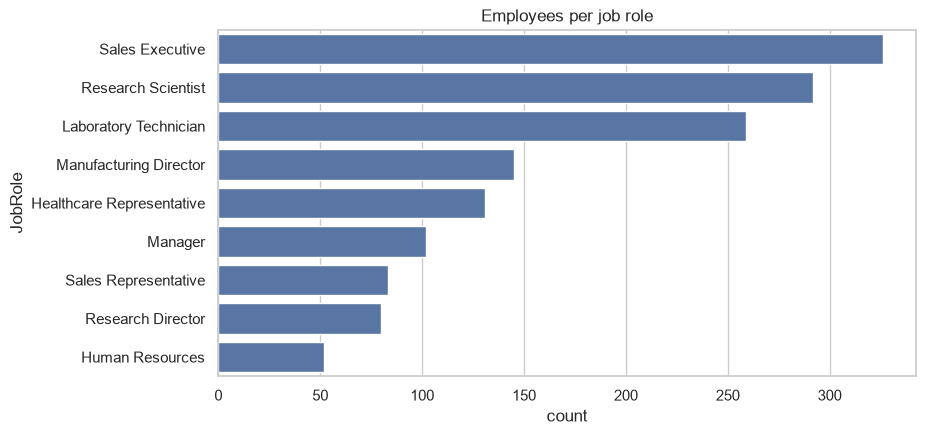

In [41]:
# ✍️ live coding
order = ibm["JobRole"].value_counts().index
sns.countplot(data =ibm, y = "JobRole", order = order)
plt.title("Employees per job role")
plt.show()


In [44]:
# ✍️ live coding
ibm.Department.value_counts()


Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

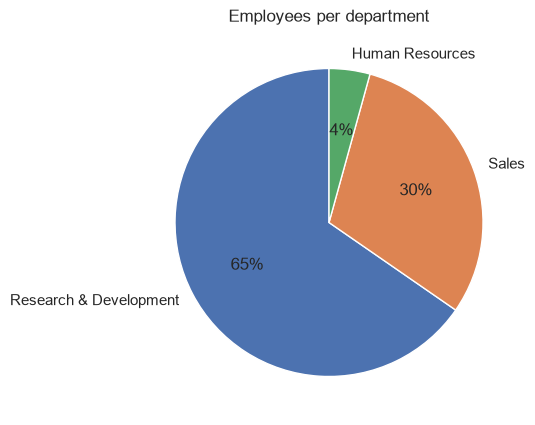

In [45]:
# 3 categories → a pie chart is OK
ibm["Department"].value_counts().plot.pie(autopct="%1.0f%%", startangle=90, figsize=(5, 5))
plt.ylabel("")
plt.title("Employees per department")
plt.show()

In [46]:
ibm["Attrition"].value_counts(normalize=True).mul(100).round(1)


Attrition
No     83.9
Yes    16.1
Name: proportion, dtype: float64

🥧 With 9 job roles a pie would be unreadable — the eye compares **lengths** much better than **angles**.
Top-N pattern for many categories: `top = df[col].value_counts().head(N).index` then `df[df[col].isin(top)]`.

**Q: What percentage of employees left the company?**

In [ ]:
# ✍️ live coding


💡 ~16% attrition — the classes are **imbalanced** (5 stayed for every 1 who left). Keep it in mind when comparing groups.

## 5. Univariate analysis — numerical variables 🔢

Three questions: **where is the center? how spread? what shape?**

### 5.1 Centrality
| Measure | Definition | Robust to outliers? |
|---|---|---|
| **mean** $\bar{x} = \frac{1}{n}\sum x_i$ | balance point | ❌ |
| **median** | middle value (50%) | ✅ |
| **mode** | most frequent value | ✅ — meaningful for discrete / ordinal data |

**Q: How much do IBM employees earn per month?**

In [ ]:
# ✍️ live coding
earthquakes
## 3 depths that show up more in the dataset
earthquakes["depth"].value_counts().head(3)

depth
10.00    3911
33.00    3692
35.00     592
15.00     384
20.00     336
         ... 
16.65       1
10.38       1
12.05       1
14.93       1
11.94       1
Name: count, Length: 3482, dtype: int64

💡 **mean > median** → a long tail of high salaries pulls the mean up. The median is the better "typical salary".
The **mode** of a continuous variable is meaningless (4 people earn exactly 2,342…) — but for discrete data it can reveal something important:

In [49]:
# ✍️ live coding
earthquakes.info()

<class 'pandas.DataFrame'>
Index: 23229 entries, 0 to 23408
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              23229 non-null  datetime64[us]
 1   latitude          23229 non-null  float64       
 2   longitude         23229 non-null  float64       
 3   type              23229 non-null  str           
 4   depth             23229 non-null  float64       
 5   magnitude         23229 non-null  float64       
 6   magnitude_type    23226 non-null  str           
 7   root_mean_square  17245 non-null  float64       
 8   id                23229 non-null  str           
 9   source            23229 non-null  str           
 10  location_source   23229 non-null  str           
 11  magnitude_source  23229 non-null  str           
 12  status            23229 non-null  str           
 13  year              23229 non-null  int32         
dtypes: datetime64[us](1), float64(5), int3

In [50]:
def dispersion(s):
    return pd.Series({
        "variance": s.var(),
        "std": s.std(),
        "range": s.max() - s.min(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "coef_variation": s.std() / s.mean(),
    }).round(2)

pd.DataFrame({
    "MonthlyIncome": dispersion(ibm["MonthlyIncome"]),
    "Age": dispersion(ibm["Age"]),
    "Magnitude": dispersion(earthquakes["magnitude"]),
})

,MonthlyIncome,Age,Magnitude
variance,22164857.07,83.46,0.18
std,4707.96,9.14,0.42
range,18990.00,42.00,3.60
IQR,5468.00,13.00,0.40
coef_variation,0.72,0.25,0.07


🕵️ **33 km** and **10 km** are not geology — they are the *default depths* seismologists assign when the depth can't be measured! The mode revealed a **data artifact**.
(Similar in the lab: prices like £9.99 are psychological price points.)

### 5.2 Dispersion
| Measure | pandas | Meaning |
|---|---|---|
| variance $s^2 = \frac{1}{n-1}\sum (x_i-\bar{x})^2$ | `.var()` | average squared distance to the mean (units²) |
| standard deviation $s$ | `.std()` | same, in the original units |
| range | `.max() - .min()` | sensitive to outliers |
| IQR $= Q_3 - Q_1$ | `.quantile(.75) - .quantile(.25)` | spread of the middle 50%, robust |
| coefficient of variation | `.std() / .mean()` | spread *relative* to the mean → compare different units |

In [ ]:
# ✍️ live coding


💡 Income varies a lot (CV ≈ 0.7); age much less (CV ≈ 0.2).

### 5.3 Shape: skewness & kurtosis
- **Skewness** (asymmetry): $0$ symmetric · $>0$ long **right** tail (mean > median) · $<0$ long **left** tail.
  Rule of thumb: $|\text{skew}| < 0.5$ ≈ symmetric · $0.5$–$1$ moderate · $>1$ strong.
- **Kurtosis** (tails): pandas gives *excess* kurtosis — $0$ like a normal distribution · $>0$ heavy tails (extreme values) · $<0$ flat, light tails.

In [ ]:
# ✍️ live coding


💡 Age ≈ symmetric · income right-skewed · depth *very* skewed with heavy tails · job satisfaction (1–4, like Amazon stars): slightly left-skewed and **flat** (negative kurtosis = answers spread over all levels).
Magnitude starts at exactly 5.5 → the dataset only contains *significant* earthquakes (a **selection** effect).

### 5.4 Visualising one numerical variable

**Histogram** → the shape. The number of `bins` changes the story!

In [52]:
# ✍️ live coding
ibm.Age.value_counts()

Age
35    78
34    77
36    69
31    69
29    68
32    61
30    60
33    58
38    58
40    57
37    50
27    48
28    48
42    46
39    42
45    41
41    40
26    39
44    33
46    33
43    32
50    30
24    26
25    26
49    24
47    24
55    22
53    19
48    19
51    19
54    18
52    18
22    16
56    14
23    14
58    14
21    13
20    11
59    10
19     9
18     8
60     5
57     4
Name: count, dtype: int64

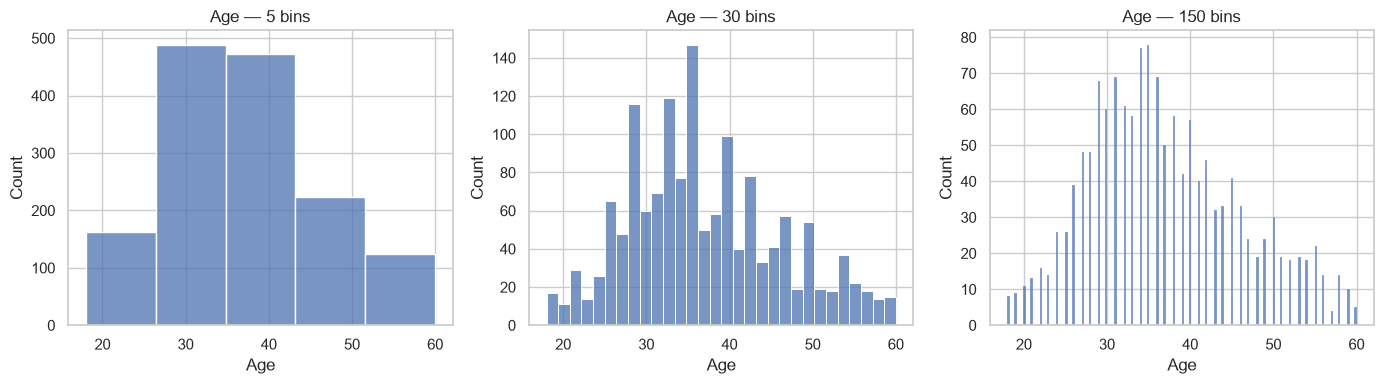

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, bins in zip(axes, [5, 30, 150]):
    sns.histplot(ibm["Age"], bins=bins, ax=ax)
    ax.set_title(f"Age — {bins} bins")
plt.tight_layout()
plt.show()

In [54]:
ibm 

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,EducationLevel,Attrition01
EmployeeNumber,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,College,1
2,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,Below College,0
4,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,College,1
5,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0,Master,0
7,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2,Below College,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2061,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,3,Male,41,4,2,Laboratory Technician,4,Married,2571,12290,4,No,17,3,3,1,17,3,3,5,2,0,3,College,0
2062,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,4,Male,42,2,3,Healthcare Representative,1,Married,9991,21457,4,No,15,3,1,1,9,5,3,7,7,1,7,Below College,0
2064,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,2,Male,87,4,2,Manufacturing Director,2,Married,6142,5174,1,Yes,20,4,2,1,6,0,3,6,2,0,3,Bachelor,0


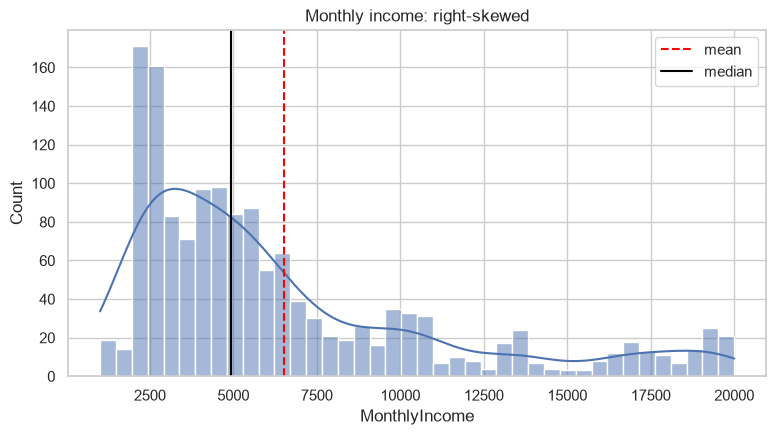

In [55]:
# ✍️ live coding
ax = sns.histplot(ibm["MonthlyIncome"], bins=40, kde=True)
ax.axvline(ibm["MonthlyIncome"].mean(), color="red", linestyle="--", label="mean")
ax.axvline(ibm["MonthlyIncome"].median(), color="black", label="median")
ax.legend()
ax.set_title("Monthly income: right-skewed")
plt.show()


🤔 **When a histogram is hard to read** — one huge bar on the left and a long empty tail (typical for **prices**!):
1. remove or cap extreme values, 2. zoom on a range, 3. use a **log scale**.

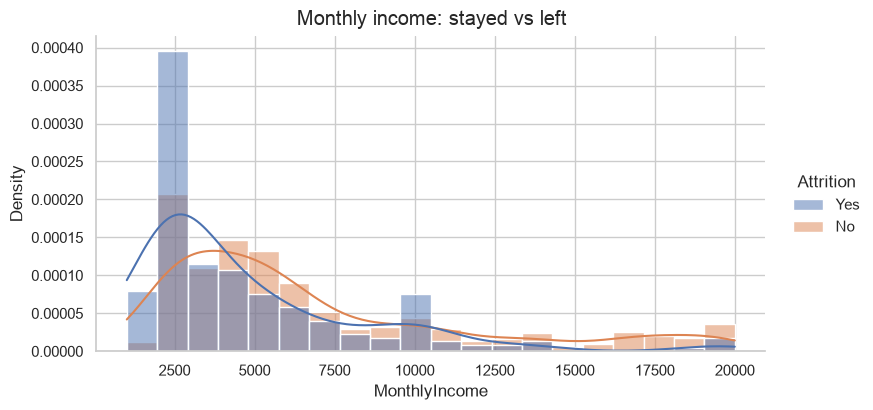

In [56]:
# ✍️ live coding
g = sns.displot(data=ibm, x="MonthlyIncome", hue="Attrition", kde=True,
                stat="density", common_norm=False, height=4, aspect=2)   # displot = the modern distplot
g.figure.suptitle("Monthly income: stayed vs left", y=1.02)
plt.show()

**Box plot** → the five-number summary: whisker · Q1 · median · Q3 · whisker, plus outlier dots beyond 1.5 × IQR.

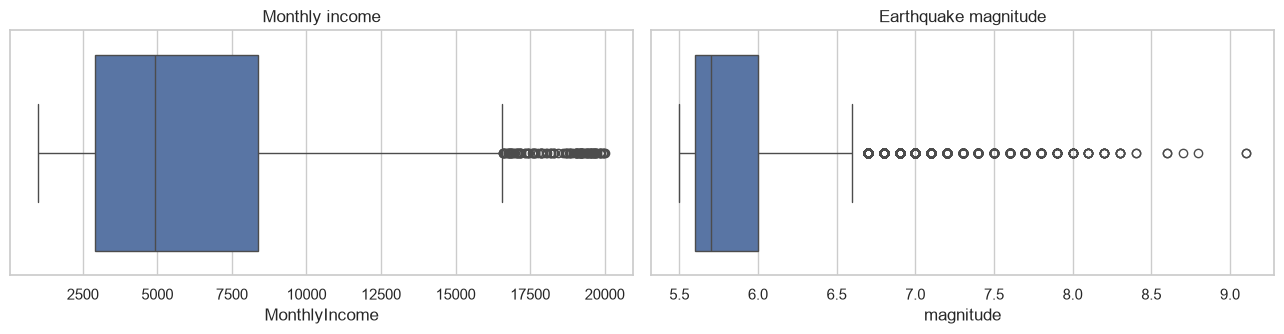

In [57]:
# ✍️ live coding
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
sns.boxplot(x=ibm["MonthlyIncome"], ax=axes[0]).set_title("Monthly income")
sns.boxplot(x=earthquakes["magnitude"], ax=axes[1]).set_title("Earthquake magnitude")
plt.tight_layout()
plt.show()

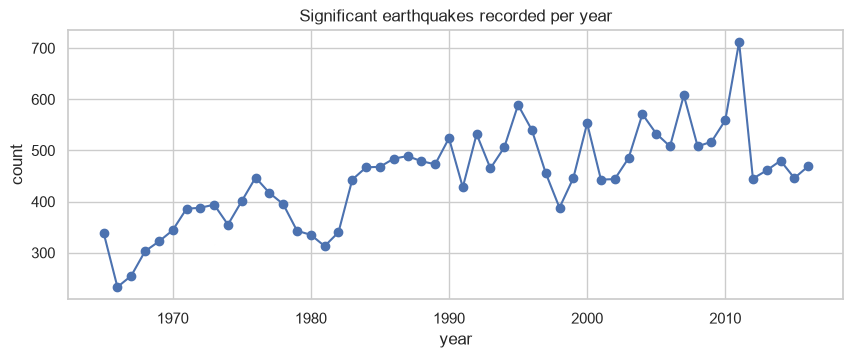

In [58]:
# ✍️ live coding
earthquakes["year"].value_counts().sort_index().plot(marker="o", figsize=(10, 3.5))
plt.title("Significant earthquakes recorded per year")
plt.ylabel("count")
plt.show()


**Q: How did the number of recorded earthquakes evolve?** (a univariate view over time)

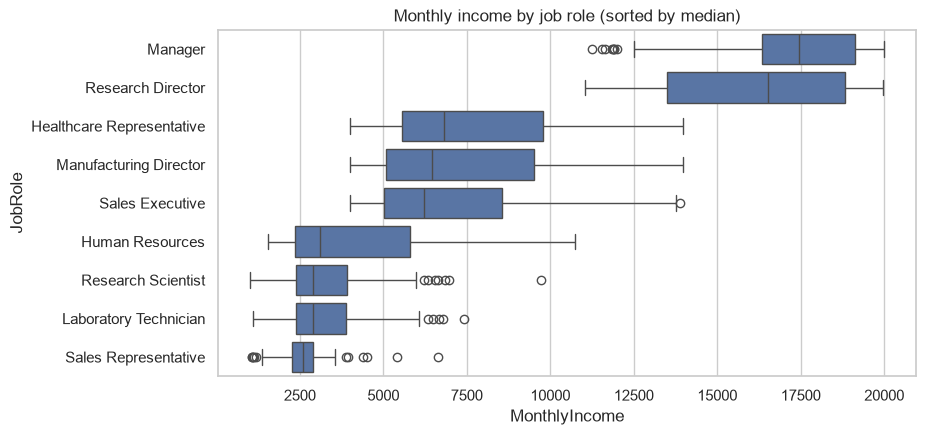

In [59]:
# ✍️ live coding
order = ibm.groupby("JobRole")["MonthlyIncome"].median().sort_values(ascending=False).index
sns.boxplot(data=ibm, y="JobRole", x="MonthlyIncome", order=order)
plt.title("Monthly income by job role (sorted by median)")
plt.show()

## ✅ Part 1 recap → Lab *EDA Univariate* (Amazon UK)

| Lab task | Where in this notebook |
|---|---|
| Frequency table, top 5 categories | §4 `value_counts()` + `head(5)` |
| Bar chart of categories (subset of top categories) | §4 sorted `countplot` + top-N pattern |
| Pie chart for top categories | §4 pie |
| Mean, median, mode of `price` | §5.1 |
| Variance, std, range, IQR of `price` | §5.2 `dispersion()` |
| Histogram of prices — *"why is it hard to read? how to solve?"* | §5.4 bins, log scale |
| Box plot of prices | §5.4 |
| Centrality & dispersion of `stars` | §5.1–5.2 (like `JobSatisfaction`) |
| Skewness & kurtosis of `stars` | §5.3 |
| Histogram of `stars` | §5.4 count plot |

---
# PART 2 · Bivariate analysis (60 min)
---
Two variables at a time: **is there a relationship? how strong? which direction?**
Strategy: put your **most important variable** (here `Attrition`) against the others.

| | **Categorical** | **Numerical** |
|---|---|---|
| **Categorical** | crosstab · χ² test · Cramér's V · stacked bar | — |
| **Numerical** | `groupby` · box / violin / bar plots | correlation (Pearson, Spearman, Kendall) · scatter · heatmap |

## 6. Categorical × Categorical 🏷️×🏷️

**Q: Do employees in some job roles leave more often?**

### 6.1 Crosstab (contingency table)

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


💡 **40%** of Sales Representatives leave vs **2%** of Research Directors. But is this difference *real* or could it be *chance*?

### 6.2 Chi-square test of independence (χ²)

- **H₀ (null hypothesis):** the two variables are **independent** (job role doesn't matter for attrition).
- The test compares the **observed** counts $O$ with the counts **expected** $E$ if H₀ were true:
  $\chi^2 = \sum \frac{(O - E)^2}{E}$ — big differences → big χ².
- **p-value** = probability of seeing differences at least this large *if H₀ were true*.
  - p < 0.05 → reject H₀ → there **is** an association.
  - p ≥ 0.05 → no evidence of association.

In [ ]:
# ✍️ live coding


### 6.3 Cramér's V — *how strong* is the association?

The p-value says *whether*, not *how much* (with big data everything becomes "significant"). Cramér's V rescales χ² to $[0, 1]$:

$$V = \sqrt{\frac{\chi^2 / n}{\min(r-1,\ c-1)}}$$

| V | < 0.1 | 0.1 – 0.3 | 0.3 – 0.5 | > 0.5 |
|---|---|---|---|---|
| strength | negligible | weak | moderate | strong |

In [ ]:
# ✍️ live coding


💡 Overtime and job role have the strongest associations with leaving — significant, but **weak** (V ≈ 0.25): many other factors matter too. **Gender: p = 0.29 → no evidence** of a difference.

### 6.4 Stacked bar chart

In [ ]:
# ✍️ live coding


## 7. Categorical × Numerical 🏷️×🔢

**Q: How does income depend on job role and education?**

### 7.0 Outliers before comparing groups?
A reusable IQR filter (you'll need it in the lab for `price`):

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


⚠️ The IQR rule removed **all the managers and research directors**! Their salaries are not errors, they are **real signal**.
Removing them would make "income by job role" meaningless. → For the rest of this section we keep **all** employees.
Lesson: *statistics detects, domain knowledge decides.* (In the Amazon lab the instructions ask you to remove price outliers — and the bonus asks you to compare with/without. Now you know why!)

### 7.1 Numbers first: `groupby`

In [ ]:
# ✍️ live coding


### 7.2 Box, violin and bar plots

| Plot | Shows | Use when |
|---|---|---|
| **box** | median, quartiles, outliers | compare typical value & spread |
| **violin** | the full shape (density) | distributions are skewed or have several peaks |
| **bar** of means | one number per group (+ confidence interval) | quick, business-friendly comparison |

With many categories: keep the **top N by count** and **sort** by the statistic.

In [60]:
# ✍️ live coding
# Significance: scipy returns the coefficient AND a p-value (H0: no correlation)
r, p = stats.pearsonr(ibm["Age"], ibm["MonthlyIncome"])
rho, p_s = stats.spearmanr(ibm["Age"], ibm["MonthlyIncome"])
print(f"Pearson r = {r:.2f} (p = {p:.1e})  |  Spearman ρ = {rho:.2f} (p = {p_s:.1e})")

Pearson r = 0.50 (p = 6.7e-93)  |  Spearman ρ = 0.47 (p = 2.2e-82)


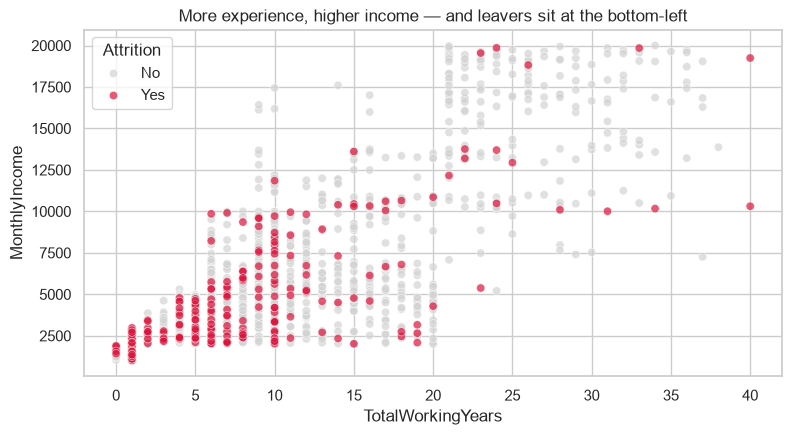

In [61]:
# ✍️ live coding
sns.scatterplot(data=ibm.sort_values("Attrition01"),          # leavers drawn last = on top
                x="TotalWorkingYears", y="MonthlyIncome", hue="Attrition", hue_order=["No", "Yes"],
                palette={"No": "lightgrey", "Yes": "crimson"}, alpha=0.7)
plt.title("More experience, higher income — and leavers sit at the bottom-left")
plt.show()


Pearson r = 0.023 | Spearman ρ = -0.037


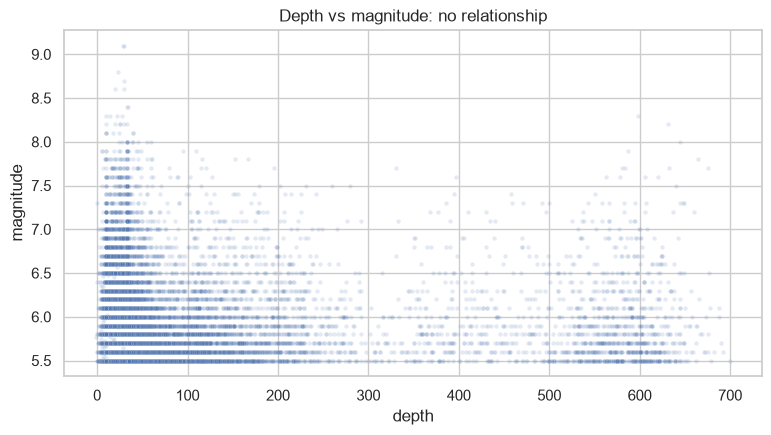

In [62]:
# ✍️ live coding
r = earthquakes["depth"].corr(earthquakes["magnitude"])
rho = earthquakes["depth"].corr(earthquakes["magnitude"], method="spearman")
print(f"Pearson r = {r:.3f} | Spearman ρ = {rho:.3f}")

sns.scatterplot(data=earthquakes, x="depth", y="magnitude", alpha=0.15, s=10)
plt.title("Depth vs magnitude: no relationship")
plt.show()

In [63]:
num_cols = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
            "JobLevel", "DistanceFromHome", "NumCompaniesWorked", "PercentSalaryHike", "Attrition01"]
corr = ibm[num_cols].corr(method="spearman")

corr 

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,JobLevel,DistanceFromHome,NumCompaniesWorked,PercentSalaryHike,Attrition01
Age,1.000000,0.471902,0.656896,0.251686,0.197978,0.489618,-0.019291,0.353213,0.007709,-0.171214
MonthlyIncome,0.471902,1.000000,0.710024,0.464315,0.394712,0.920429,0.002512,0.190307,-0.033767,-0.198305
TotalWorkingYears,0.656896,0.710024,1.000000,0.594193,0.492721,0.734678,-0.002912,0.315196,-0.025528,-0.199002
YearsAtCompany,0.251686,0.464315,0.594193,1.000000,0.854000,0.472283,0.010513,-0.171070,-0.054117,-0.190419
YearsInCurrentRole,0.197978,0.394712,0.492721,0.854000,1.000000,0.391085,0.013708,-0.127673,-0.025528,-0.180623
JobLevel,0.489618,0.920429,0.734678,0.472283,0.391085,1.000000,0.022148,0.178270,-0.032453,-0.190370
DistanceFromHome,-0.019291,0.002512,-0.002912,0.010513,0.013708,0.022148,1.000000,-0.009592,0.029666,0.079248
NumCompaniesWorked,0.353213,0.190307,0.315196,-0.171070,-0.127673,0.178270,-0.009592,1.000000,0.000046,0.030505
PercentSalaryHike,0.007709,-0.033767,-0.025528,-0.054117,-0.025528,-0.032453,0.029666,0.000046,1.000000,-0.023612
Attrition01,-0.171214,-0.198305,-0.199002,-0.190419,-0.180623,-0.190370,0.079248,0.030505,-0.023612,1.000000


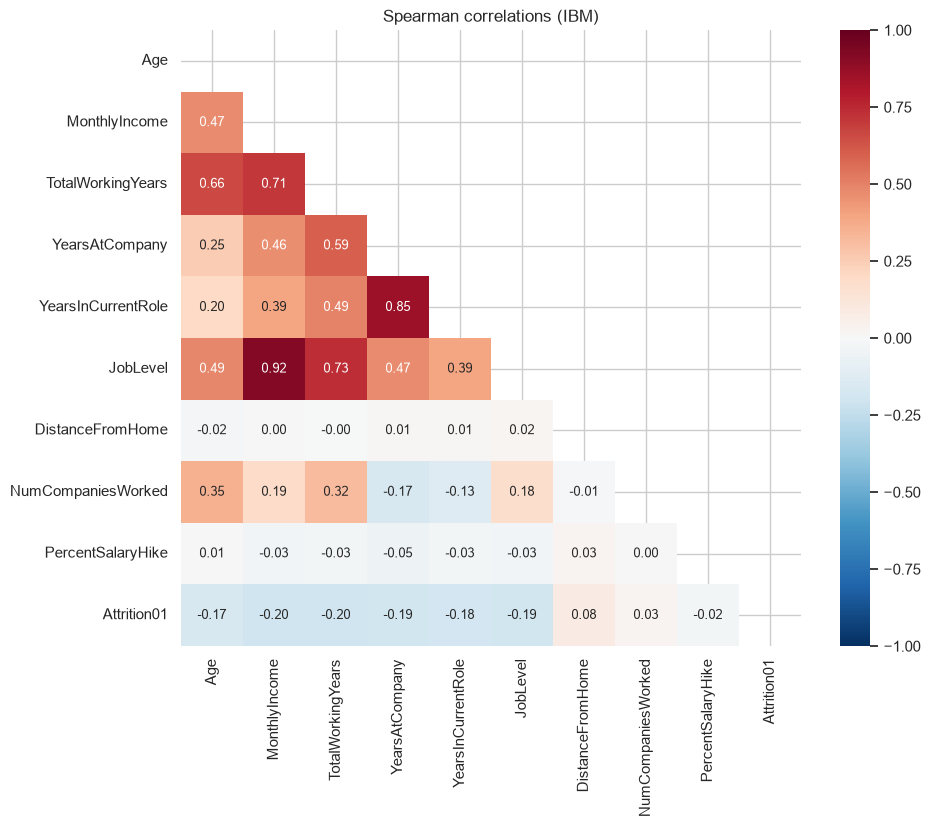

In [64]:
mask = np.triu(np.ones_like(corr, dtype=bool))       # the upper triangle is a mirror → hide it
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 9}, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman correlations (IBM)")
plt.show()

💡 A bar plot hides the distribution — two groups with the same mean can look very different in a violin. **Bars for communication, box/violin for exploration.**

**Q: Do people who leave earn less?** — the most important variable against a numerical one.

In [ ]:
# ✍️ live coding


💡 `common_norm=False` normalises each group separately — essential when groups have very different sizes (84% vs 16%).

## 8. Numerical × Numerical 🔢×🔢

### 8.1 Covariance → correlation
**Covariance** $\text{cov}(X,Y) = \frac{1}{n-1}\sum (x_i - \bar{x})(y_i - \bar{y})$ is positive when X and Y move together — but it depends on the units (years × €?).
**Correlation** divides by both standard deviations → a pure number in $[-1, 1]$.

### 8.2 Pearson vs Spearman vs Kendall

| | **Pearson** $r$ | **Spearman** $\rho$ | **Kendall** $\tau$ |
|---|---|---|---|
| Measures | **linear** relationship | **monotonic** relationship (always up / always down) | monotonic, via pairs |
| How | on the values | Pearson on the **ranks** | (concordant − discordant pairs) / all pairs |
| Outliers | ❌ very sensitive | ✅ robust | ✅ robust |
| Use when | both ≈ normal, straight-line pattern | skewed data, **ordinal** data (ratings!), outliers | small samples, many ties |
| pandas | `corr()` | `corr(method="spearman")` | `corr(method="kendall")` |

$$r = \frac{\text{cov}(X,Y)}{s_X\, s_Y} \qquad\qquad \rho = r\big(\text{rank}(X),\ \text{rank}(Y)\big)$$

Strength of $|r|$: < 0.1 none · 0.1–0.3 weak · 0.3–0.5 moderate · > 0.5 strong. The **sign** gives the direction.
Kendall's τ is usually smaller in absolute value than ρ — compare τ with τ, not with ρ.

Four toy examples make the differences obvious 👇

In [ ]:
# ✍️ live coding


1. **Linear** → both high.
2. **Monotonic curve** → Spearman ≈ 1 (always increasing), Pearson lower (not a straight line).
3. **One outlier** → Pearson collapses, Spearman barely moves.
4. **U-shape** → both ≈ 0 although the relationship is **strong**! Correlation only sees monotonic patterns → **always plot**.

### 8.3 On IBM data
**Q: Is income correlated with age? with experience?**

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


💡 Moderate-to-strong positive correlations, all highly significant (p ≪ 0.05).
⚠️ **Correlation ≠ causation**: age doesn't *cause* income — experience and job level drive both.

**Q: Are deeper earthquakes stronger?**

In [ ]:
# ✍️ live coding


💡 r ≈ 0: knowing the depth tells you nothing about the magnitude. With 23,000 points use **transparency** (`alpha`) — otherwise it's one big blob. The horizontal stripes appear because magnitudes are rounded to 0.1.

### 8.4 Correlation heatmap — all pairs at once

In [ ]:
# ✍️ live coding


💡 Use a **diverging** palette centred on 0 with `vmin=-1, vmax=1`, otherwise the colours lie.
`MonthlyIncome` ↔ `JobLevel` ≈ 0.9: almost the same information (useful to know before modelling!). Attrition correlates **negatively** with age, experience and income.

### 8.5 Is it normally distributed? The QQ plot

Pearson, t-tests and z-scores assume roughly **normal** data. A **QQ plot** puts the quantiles of your data against those of a perfect normal distribution:
- points on the **straight line** → normal ✅
- curve bending **up on the right** → right skew (long right tail) — typical for **prices** and incomes
- **S-shape** → tails heavier or lighter than normal

In [ ]:
# ✍️ live coding


💡 Money-like variables (prices, incomes) are often right-skewed; a **log transform** helps. Here it is not enough: the flat top shows incomes are **capped at 20,000** and there are several salary bands — real data is rarely perfectly normal, and that's fine. Use Spearman when in doubt.

### 8.6 With vs without outliers (lab bonus)

In [ ]:
# ✍️ live coding


💡 Removing the top earners weakens the age–income relationship and lowers the median: outlier decisions **change conclusions** — always report what you removed.

## ✅ Part 2 recap → Lab *EDA Bivariate* (Amazon UK)

| Lab task | Where in this notebook |
|---|---|
| Crosstab `category` × `isBestSeller`; proportion of best-sellers, sorted | §6.1 `crosstab(normalize="index")` (JobRole × Attrition) |
| Chi-square test of independence | §6.2 `stats.chi2_contingency` |
| Cramér's V | §6.3 `association(..., method="cramer")` |
| Stacked bar chart | §6.4 |
| Remove price outliers with IQR | §7.0 `remove_outliers_iqr()` |
| Violin plot of price by category (top 20) | §7.2 violin + top-N filter |
| Bar chart of average price (top 10); highest average price | §7.1 `groupby` + §7.2 barplot |
| Box plots of `stars` by category; highest median | §7.2 box plot sorted by median |
| Correlation `price` vs `stars` + significance | §8.2–8.3 Pearson / Spearman + p-value |
| Scatter plot | §8.3 |
| Correlation heatmap | §8.4 |
| QQ plot of prices | §8.5 |
| Bonus: with vs without outliers | §7.0 + §8.6 |

### 🎯 Key ideas
- Clean first, keep the raw data, put every decision in a **function**.
- **Type first**, then the statistic and the plot.
- Median & IQR for skewed data; mean & std for symmetric data.
- p-value = *is there* a relationship; Cramér's V / correlation = *how strong*.
- Pearson = linear & fragile · Spearman = monotonic & robust · **always plot**.
- Outliers can be errors **or** the most interesting people in the data.
- Correlation ≠ causation.